In [43]:
from langgraph.graph import StateGraph , START , END
from typing import TypedDict 
from pydantic import BaseModel , Field
from langchain.output_parsers.structured import ResponseSchema
import operator

In [44]:
from langchain.output_parsers import StructuredOutputParser, ResponseSchema
from langchain.prompts import ChatPromptTemplate

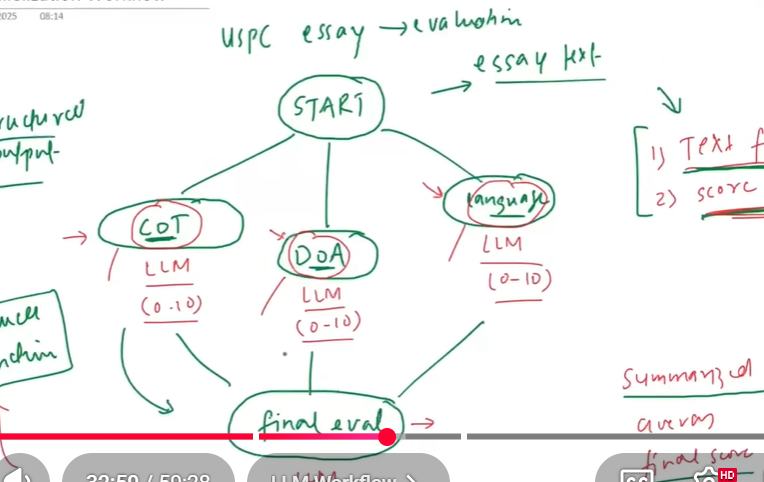

In [45]:
response_schemas = [
    ResponseSchema(name="feedback", description="Detailed feedback for the essay"),
    ResponseSchema(name="score", description = 'score out of 10', ge=0 , le = 10),
]


In [46]:

parser = StructuredOutputParser.from_response_schemas(response_schemas)
format_instructions = parser.get_format_instructions()

In [47]:
from groq import Groq
import json


In [48]:
from typing import Annotated


class UPSCState(TypedDict):
    essay : str
    language_feedback : str
    analysis_feedback : str
    clarity_feedback : str
    overall_feedback : str
    individual_score : Annotated[list[int] , operator.add]
    avg_score : float

    # ALL 3 NODES , COT , DOA and language , all three will run paralley and return invidiual score , how do we merge the score of them to have one list , say each nodes gives output for individual score [2] , [3] , [4] , we need to merge them in onestate before sending ahead , we will use a reducer , operator.add to merge them
    # operator.add does [2] + [3] + [4] , merging them to [2,3,4]

In [49]:
def evaluate_language(state : UPSCState) -> UPSCState:
    prompt = ChatPromptTemplate.from_template("""Evaluate the language quality of the following essay and provide a feedback and assign a score out of 10 {essay}\n
    {format_instructions}""")

    messages = prompt.format_messages(
        essay = """ In the 21st century, technology has revolutionized nearly every aspect of human life, and education is no exception. Among all technological advancements, Artificial Intelligence (AI) has emerged as a transformative force that is reshaping how students learn and how educators teach. From personalized learning platforms to automated grading systems, AI has the potential to make education more efficient, accessible, and engaging.

One of the most significant impacts of AI in education is personalized learning. Traditional classrooms often follow a one-size-fits-all approach, which may not cater to the unique learning pace or style of each student. AI-driven systems, however, can analyze a student’s performance in real time and adjust the curriculum accordingly. Platforms like Khan Academy and Coursera already use machine learning algorithms to recommend specific exercises and lessons based on individual progress, thereby creating a more adaptive and effective learning environment.

Furthermore, AI enhances accessibility for students with disabilities. For instance, speech recognition technology can assist students with visual impairments, while AI-powered translation tools can help break down language barriers for international learners. This inclusivity allows students from diverse backgrounds to participate more actively in the educational process, fostering equality and diversity in classrooms.

Another major benefit is automation. Teachers spend a significant amount of time grading assignments and preparing administrative reports—tasks that AI can handle efficiently. Automated grading systems and AI chatbots can provide instant feedback, allowing educators to focus on more creative and human-centered aspects of teaching, such as mentoring and critical thinking discussions.

However, the integration of AI also raises ethical and practical challenges. Data privacy is a major concern, as AI systems rely on vast amounts of student data to function effectively. There is also the risk of over-reliance on technology, which might reduce the importance of human connection and emotional intelligence in education. Balancing AI-driven efficiency with the need for human empathy remains a key challenge for future educators and policymakers.

In conclusion, AI is not merely a tool but a catalyst for a new era of education. When implemented responsibly, it can create learning environments that are more personalized, inclusive, and effective. However, it is essential to ensure that technology complements rather than replaces the human touch that lies at the heart of education.""",
        format_instructions = format_instructions
    )

    client = Groq(api_key="YOUR_GROQ_API_KEY")
    
    completion = client.chat.completions.create(
    model="openai/gpt-oss-20b",
    messages=[{"role": m.type, "content": m.content} for m in messages],
    temperature=0,
)
    
    raw_output = completion.choices[0].message.content
    parsed = parser.parse(raw_output)

    return {'language_feedback' : parsed['feedback'] ,'individual_score' : parsed['score']}
# function in langgraoh always return a dict , the state which we return is also a dict , there we often say that "return state in functions in langgraph"
# reality is , you can return dict in functions in langgraph

    



    
    

In [50]:
def evaluate_analysis(state : UPSCState) -> UPSCState:
    prompt = ChatPromptTemplate.from_template("""Evaluate the depth of analysis of the following essay and provide a feedback and assign a score out of 10 {essay}\n
    {format_instructions}""")

    messages = prompt.format_messages(
        essay = """ In the 21st century, technology has revolutionized nearly every aspect of human life, and education is no exception. Among all technological advancements, Artificial Intelligence (AI) has emerged as a transformative force that is reshaping how students learn and how educators teach. From personalized learning platforms to automated grading systems, AI has the potential to make education more efficient, accessible, and engaging.

One of the most significant impacts of AI in education is personalized learning. Traditional classrooms often follow a one-size-fits-all approach, which may not cater to the unique learning pace or style of each student. AI-driven systems, however, can analyze a student’s performance in real time and adjust the curriculum accordingly. Platforms like Khan Academy and Coursera already use machine learning algorithms to recommend specific exercises and lessons based on individual progress, thereby creating a more adaptive and effective learning environment.

Furthermore, AI enhances accessibility for students with disabilities. For instance, speech recognition technology can assist students with visual impairments, while AI-powered translation tools can help break down language barriers for international learners. This inclusivity allows students from diverse backgrounds to participate more actively in the educational process, fostering equality and diversity in classrooms.

Another major benefit is automation. Teachers spend a significant amount of time grading assignments and preparing administrative reports—tasks that AI can handle efficiently. Automated grading systems and AI chatbots can provide instant feedback, allowing educators to focus on more creative and human-centered aspects of teaching, such as mentoring and critical thinking discussions.

However, the integration of AI also raises ethical and practical challenges. Data privacy is a major concern, as AI systems rely on vast amounts of student data to function effectively. There is also the risk of over-reliance on technology, which might reduce the importance of human connection and emotional intelligence in education. Balancing AI-driven efficiency with the need for human empathy remains a key challenge for future educators and policymakers.

In conclusion, AI is not merely a tool but a catalyst for a new era of education. When implemented responsibly, it can create learning environments that are more personalized, inclusive, and effective. However, it is essential to ensure that technology complements rather than replaces the human touch that lies at the heart of education.""",
        format_instructions = format_instructions
    )

    client = Groq(api_key="YOUR_GROQ_API_KEY")
    
    completion = client.chat.completions.create(
    model="openai/gpt-oss-20b",
    messages=[{"role": m.type, "content": m.content} for m in messages],
    temperature=0,
)
    
    raw_output = completion.choices[0].message.content
    parsed = parser.parse(raw_output)

    return {'analysis_feedback' : parsed['feedback'] ,'individual_score' : parsed['score']}
# function in langgraoh always return a dict , the state which we return is also a dict , there we often say that "return state in functions in langgraph"
# reality is , you can return dict in functions in langgraph

    



    
    

In [51]:
def evaluate_thought(state : UPSCState) -> UPSCState:
    prompt = ChatPromptTemplate.from_template("""Evaluate the clarity of thought of the following essay and provide a feedback and assign a score out of 10 {essay}\n
    {format_instructions}""")

    messages = prompt.format_messages(
        essay = """ In the 21st century, technology has revolutionized nearly every aspect of human life, and education is no exception. Among all technological advancements, Artificial Intelligence (AI) has emerged as a transformative force that is reshaping how students learn and how educators teach. From personalized learning platforms to automated grading systems, AI has the potential to make education more efficient, accessible, and engaging.

One of the most significant impacts of AI in education is personalized learning. Traditional classrooms often follow a one-size-fits-all approach, which may not cater to the unique learning pace or style of each student. AI-driven systems, however, can analyze a student’s performance in real time and adjust the curriculum accordingly. Platforms like Khan Academy and Coursera already use machine learning algorithms to recommend specific exercises and lessons based on individual progress, thereby creating a more adaptive and effective learning environment.

Furthermore, AI enhances accessibility for students with disabilities. For instance, speech recognition technology can assist students with visual impairments, while AI-powered translation tools can help break down language barriers for international learners. This inclusivity allows students from diverse backgrounds to participate more actively in the educational process, fostering equality and diversity in classrooms.

Another major benefit is automation. Teachers spend a significant amount of time grading assignments and preparing administrative reports—tasks that AI can handle efficiently. Automated grading systems and AI chatbots can provide instant feedback, allowing educators to focus on more creative and human-centered aspects of teaching, such as mentoring and critical thinking discussions.

However, the integration of AI also raises ethical and practical challenges. Data privacy is a major concern, as AI systems rely on vast amounts of student data to function effectively. There is also the risk of over-reliance on technology, which might reduce the importance of human connection and emotional intelligence in education. Balancing AI-driven efficiency with the need for human empathy remains a key challenge for future educators and policymakers.

In conclusion, AI is not merely a tool but a catalyst for a new era of education. When implemented responsibly, it can create learning environments that are more personalized, inclusive, and effective. However, it is essential to ensure that technology complements rather than replaces the human touch that lies at the heart of education.""",
        format_instructions = format_instructions
    )

    client = Groq(api_key="YOUR_GROQ_API_KEY")
    
    completion = client.chat.completions.create(
    model="openai/gpt-oss-20b",
    messages=[{"role": m.type, "content": m.content} for m in messages],
    temperature=0,
)
    
    raw_output = completion.choices[0].message.content
    parsed = parser.parse(raw_output)

    return {'clarity_feedback' : parsed['feedback'] ,'individual_score' : parsed['score']}
# function in langgraoh always return a dict , the state which we return is also a dict , there we often say that "return state in functions in langgraph"
# reality is , you can return dict in functions in langgraph

    



    
    

In [52]:
def final_evaluation(state : UPSCState) -> UPSCState:
    prompt =f"""Based on the following feedbacks create a summarized feedback \n language feedback {state['language_feedback']}\n depth of analysis feedback {state['analysis_feedback']} \n clarity of thought feedback {state['clarity_feedback']}
    """

   

    client = Groq(api_key="YOUR_GROQ_API_KEY")
    
    completion = client.chat.completions.create(
    model="openai/gpt-oss-20b",
      messages=[
      {
        "role": "user",
        "content": prompt
      }
    ],
    temperature=1,
    max_completion_tokens=8192,
    top_p=1,
    reasoning_effort="medium",
    stream=True,
    stop=None
)
    answer = ""
    for chunk in completion:
        answer += chunk.choices[0].delta.content or ""

    state['overall_feedback'] = answer
    state['avg_score'] = sum(state['individual_score'])/(len(state['individual_score']))


    return state
# function in langgraoh always return a dict , the state which we return is also a dict , there we often say that "return state in functions in langgraph"
# reality is , you can return dict in functions in langgraph

    



    
    

In [53]:
graph = StateGraph(UPSCState)

graph.add_node('evaluate_language' , evaluate_language)

graph.add_node('evaluate_analysis' , evaluate_analysis)


graph.add_node('evaluate_thought' , evaluate_thought)

graph.add_node('final_evaluation' , final_evaluation)

graph.add_edge(START , 'evaluate_language' )
graph.add_edge(START , 'evaluate_analysis' )
graph.add_edge(START , 'evaluate_thought' )

graph.add_edge('evaluate_thought' , 'final_evaluation' )
graph.add_edge( 'evaluate_language' , 'final_evaluation')
graph.add_edge( 'evaluate_analysis' , 'final_evaluation')

graph.add_edge('final_evaluation' , END)



In [54]:
workflow = graph.compile()

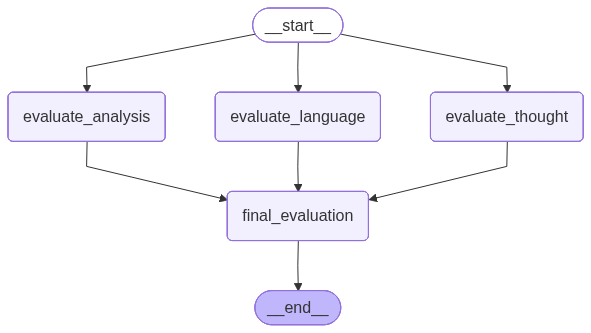

In [55]:
workflow

In [56]:
essay = """ 

One of the most significant impacts of AI in education is personalized learning. Traditional classrooms often follow a one-size-fits-all approach, which may not cater to the unique learning pace or style of each student. AI-driven systems, however, can analyze a student’s performance in real time and adjust the curriculum accordingly. Platforms like Khan Academy and Coursera already use machine learning algorithms to recommend specific exercises and lessons based on individual progress, thereby creating a more adaptive and effective learning environment.

Furthermore, AI enhances accessibility for students with disabilities. For instance, speech recognition technology can assist students with visual impairments, while AI-powered translation tools can help break down language barriers for international learners. This inclusivity allows students from diverse backgrounds to participate more actively in the educational process, fostering equality and diversity in classrooms.

Another major benefit is automation. Teachers spend a significant amount of time grading assignments and preparing administrative reports—tasks that AI can handle efficiently. Automated grading systems and AI chatbots can provide instant feedback, allowing educators to focus on more creative and human-centered aspects of teaching, such as mentoring and critical thinking discussions.

However, the integration of AI also raises ethical and practical challenges. Data privacy is a major concern, as AI systems rely on vast amounts of student data to function effectively. There is also the risk of over-reliance on technology, which might reduce the importance of human connection and emotional intelligence in education. Balancing AI-driven efficiency with the need for human empathy remains a key challenge for future educators and policymakers.

In conclusion, AI is not merely a tool but a catalyst for a new era of education. When implemented responsibly,
"""

In [57]:
initial_state = {
    "essay" : essay
}

In [58]:
final_state = workflow.invoke(initial_state)

BadRequestError: Error code: 400 - {'error': {'message': "'messages.0' : discriminator property 'role' has invalid value", 'type': 'invalid_request_error'}}